<a href="https://colab.research.google.com/github/christiana-adisa/Applied-ML-at-Scale/blob/main/ALS_with_Embeddings_Parallel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit, prange
import random

In [3]:
# MAP users to index
ratings = np.loadtxt("/content/drive/MyDrive/ml-32m/ml-32m/ratings.csv", delimiter=",", dtype= None, encoding='utf-8', skiprows=1)
# np.loadtxt("/content/drive/MyDrive/ml-32m/ml-32m/movies.csv", delimiter=",", dtype= None, encoding='utf-8', skiprows=1)
# np.loadtxt("/content/drive/MyDrive/ml-32m/ml-32m/.csv", delimiter=",", dtype= None, encoding='utf-8', skiprows=1)

In [17]:
# # Before parallelizing
# #Training on all 32m data
# M = len(data_by_user_32m_train)
# N = len(data_by_item_32m_train)

# mean = 0
# variance = 1
# k= 5

# U = np.random.normal(mean, (variance**0.5), size=(M, k))
# V = np.random.normal(mean, (variance**0.5), size=(N, k))


# lambda_val = 0.5 #precision parameter.  try different values
# gamma_val = 0.1 #bias regularizer. try different values
# tau_val = 5 #vector regularizer. try different values

# rmse_train_32m_list = []
# rmse_test_32m_list = []

# rmse_32m_list = []
# loss_train_func = []
# loss_test_func = []

# user_biases = np.zeros(M)
# item_biases = np.zeros(N)

# epochs = 10

# for epoch in range(epochs):
#   for i in prange(M):
#     bias = 0
#     item_counter = 0
#     for (n,r) in data_by_user_32m_train[i]:
#       bias += lambda_val * (r - (np.dot(U[i], V[n]) + item_biases[n]))
#       item_counter += 1
#     bias = bias / (lambda_val * item_counter + gamma_val)
#     user_biases[i] = bias

#     #     updating user vector
#     # user_vector = np.zeros(k)
#     v_squared = np.zeros((k,k))
#     v_sum_biases = np.zeros(k)
#     for (n,r) in data_by_user_32m_train[i]:
#       v_squared += np.outer(V[n], V[n])
#       v_sum_biases += V[n] * (r - user_biases[i] - item_biases[n])

#     user_vector = np.linalg.inv(lambda_val * v_squared + tau_val*np.identity(k)) @ (lambda_val  * v_sum_biases)
#     U[i] = user_vector


#   for i in prange(N):
#     bias = 0
#     item_counter = 0
#     for (n,r) in data_by_item_32m_train[i]:
#       bias += lambda_val * (r - (np.dot(U[n], V[i]) + user_biases[n]))
#       item_counter += 1
#     bias = bias / (lambda_val * item_counter + gamma_val)
#     item_biases[i] = bias

#     # undating item vector
#     u_squared = np.zeros((k,k))
#     u_sum_biases = np.zeros(k)
#     for (n,r) in data_by_item_32m_train[i]:
#       u_squared += np.outer(U[n], U[n])
#       u_sum_biases += U[n] * (r - user_biases[n] - item_biases[i])
#     item_vector = np.linalg.inv(lambda_val * u_squared + tau_val*np.identity(k)) @ (lambda_val  * u_sum_biases)
#     V[i] = item_vector

#   train_user_error = 0
#   for i in range(M):
#     for (n,r) in data_by_user_32m_train[i]:
#       train_user_error += (r - np.dot(U[i], V[n]) -  user_biases[i] - item_biases[n])**2
#     user_train_loss = (((lambda_val/2) * train_user_error) + ((tau_val/2)* np.sum(U**2)) + ((tau_val/2)* np.sum(V**2)) +  ((gamma_val/2) * np.sum(user_biases**2)) + ((gamma_val/2) * np.sum(item_biases**2)))

#   test_user_error = 0
#   for i in range(M):
#     for (n,r) in data_by_user_32m_test[i]:
#       test_user_error += (r - np.dot(U[i], V[n]) - user_biases[i] - item_biases[n])**2
#     # user_test_loss = (((lambda_val/2) * test_user_error) + ((gamma_val/2) * np.sum(user_biases**2)) + ((gamma_val/2) * np.sum(item_biases**2)))

#   # print(user_train_loss)
#   loss_train_func.append(user_train_loss)


#   # print(user_test_loss)
#   # loss_test_func.append(user_test_loss)

#   # This is the root mean square for my train and test set
#   rmse_train = (train_user_error/train_32m_rating)**0.5
#   rmse_test = (test_user_error/test_32m_rating)**0.5


#   print(f"Epochs {epoch+1} | Loss: {user_train_loss: .4f} | RMSE Train: {rmse_train: .3f} | RMSE Test: {rmse_test :.3f}")

#   # rmse_test = (test_user_error/test_rating)**0.5


#   rmse_train_32m_list.append(rmse_train)
#   rmse_test_32m_list.append(rmse_test)

#   # print(rmse_train)
#   # print(rmse_test)


# # print(loss_func)
# # print(rmse_list)

In [4]:
# Reproducible split
random.seed(42)

# Map user and items to indices

user_32m_dict = {}
index_user_32m_list = []

item_32m_dict = {}
index_item_32m_list = []

for row in ratings:
    user_id = row[0]
    item_id = row[1]

    if user_id not in user_32m_dict:
        user_32m_dict[user_id] = len(index_user_32m_list)
        index_user_32m_list.append(user_id)

    if item_id not in item_32m_dict:
        item_32m_dict[item_id] = len(index_item_32m_list)
        index_item_32m_list.append(item_id)

M = len(index_user_32m_list)
N = len(index_item_32m_list)

print("Number of users:", M)
print("Number of items:", N)


data_by_user_32m_train = [[] for _ in range(M)]
data_by_user_32m_test = [[] for _ in range(M)]

data_by_item_32m_train = [[] for _ in range(N)]
data_by_item_32m_test = [[] for _ in range(N)]

cut_off = 0.8

for row in ratings:
    rand_num = random.random()
    user_id = row[0]
    item_id = row[1]
    rating = float(row[2])

    u_idx = user_32m_dict[user_id]
    i_idx = item_32m_dict[item_id]

    if rand_num < cut_off:
        data_by_user_32m_train[u_idx].append((i_idx, rating))
        data_by_item_32m_train[i_idx].append((u_idx, rating))
    else:
        data_by_user_32m_test[u_idx].append((i_idx, rating))
        data_by_item_32m_test[i_idx].append((u_idx, rating))

# Count actual ratings
train_32m_rating = sum(map(len, data_by_user_32m_train))
test_32m_rating = sum(map(len, data_by_user_32m_test))

print("Training ratings:", train_32m_rating)
print("Testing ratings:", test_32m_rating)

Number of users: 200948
Number of items: 84432
Training ratings: 25602894
Testing ratings: 6397310


In [7]:
# Because I am using Numba to parallelize, this is to convert the list of list to flat arrays
def to_flat_arrays(grouped_data):
    offsets = np.zeros(len(grouped_data) + 1, dtype=np.int64)

    for i, group in enumerate(grouped_data):
        offsets[i + 1] = offsets[i] + len(group)

    total = offsets[-1] # total offset

    indices = np.empty(total, dtype=np.int64) # index
    values = np.empty(total, dtype=np.float64) # ratings

    index = 0

    for group in grouped_data:
        for idx, rating in group:
            indices[index] = idx
            values[index] = rating
            index += 1

    return offsets, indices, values


# Training ratings grouped by user
user_offsets, user_items, user_ratings = to_flat_arrays(
    data_by_user_32m_train
)

# Training ratings grouped by item
item_offsets, item_users, item_ratings = to_flat_arrays(
    data_by_item_32m_train
)

# Test ratings grouped by user
test_user_offsets, test_user_items, test_user_ratings = to_flat_arrays(
    data_by_user_32m_test
)

print("Training arrays prepared.")
print("User offsets:", user_offsets.shape)
print("Item offsets:", item_offsets.shape)

Training arrays prepared.
User offsets: (200949,)
Item offsets: (84433,)


In [18]:
# Hyperparameters
mean = 0
variance = 1

k = 15

lambda_val = 0.5
gamma_val = 0.1
tau_val = 5.0

epochs = 20

# Latent factors
U = np.random.normal(mean, (variance**0.5), size=(M, k))
V = np.random.normal(mean, (variance**0.5), size=(N, k))

# User and item biases
user_biases = np.zeros(M)
item_biases = np.zeros(N)

# Metrics
rmse_train_32m_list = []
rmse_test_32m_list = []
loss_train_func = []

In [9]:
@njit(parallel=True, fastmath=True)
def update_users(U, V, user_biases, item_biases, offsets, indices, values, lambda_val, gamma_val, tau_val, k):
    M = len(offsets) - 1
    identity_k = np.eye(k)

    for i in prange(M):
        start = offsets[i]
        end = offsets[i + 1]
        count = end - start

        if count == 0:
            user_biases[i] = 0
            U[i] = 0
            continue

        # Update user bias
        bias = 0.0
        for u in range(start, end):
            n = indices[u] #acess the item index for user u
            r = values[u] #access the rating for user u

            bias += lambda_val * (r - (np.dot(U[i], V[n]) + item_biases[n]))
            bias = bias / (lambda_val * count + gamma_val)
        user_biases[i] = bias

        # Update user latent vector
        v_squared = np.zeros((k, k))
        v_sum_biases = np.zeros(k)

        for p in range(start, end):
            n = indices[p]
            r = values[p]

            v = V[n]
            v_squared += np.outer(v, v)
            v_sum_biases += v * (r - user_biases[i] - item_biases[n])


        user_vector = np.linalg.inv(lambda_val * v_squared + tau_val*np.identity(k)) @ (lambda_val  * v_sum_biases)
        U[i] = user_vector

In [10]:
@njit(parallel=True, fastmath=True)
def update_items(U, V, user_biases, item_biases, offsets, indices, values,lambda_val, gamma_val, tau_val, k):
    N = len(offsets) - 1
    identity_k = np.eye(k)

    for i in prange(N):
        start = offsets[i]
        end = offsets[i + 1]
        count = end - start

        if count == 0:
            item_biases[i] = 0
            V[i] = 0
            continue

        # Update item bias
        bias = 0
        for v in range(start, end):
            u = indices[v]
            r = values[v]

            bias += lambda_val * (r - (np.dot(U[u], V[i]) + user_biases[u]))
            bias = bias / (lambda_val * count + gamma_val)

        item_biases[i] = bias

        # Update item latent vector
        u_squared = np.zeros((k, k))
        u_sum_biases = np.zeros(k)

        for p in range(start, end):
            u = indices[p]
            r = values[p]

            u_vec = U[u]
            u_squared += np.outer(u_vec, u_vec)
            u_sum_biases += u_vec * (r - user_biases[u] - item_biases[i])
        item_vector = np.linalg.inv(lambda_val * u_squared + tau_val*np.identity(k)) @ (lambda_val  * u_sum_biases)
        V[i] = item_vector

In [11]:
@njit(parallel=True, fastmath=True)
def calculate_squared_errors(U, V, user_biases, item_biases,offsets, indices, values):
    M = len(offsets) - 1
    errors = np.zeros(M)

    for i in prange(M):
      total = 0
      for p in range(offsets[i], offsets[i + 1]):
          n = indices[p]
          r = values[p]

          prediction = (np.dot(U[i], V[n])+ user_biases[i]+ item_biases[n])

          total += (r - prediction) ** 2
      errors[i] = total

    return errors

In [19]:
for epoch in range(epochs):
    # updating the user vector and item vectors in parallel
    update_users(U, V, user_biases, item_biases,user_offsets, user_items, user_ratings,lambda_val, gamma_val, tau_val, k)

    update_items(U, V, user_biases, item_biases, item_offsets, item_users, item_ratings, lambda_val, gamma_val, tau_val, k)

    train_errors = calculate_squared_errors(U, V, user_biases, item_biases,user_offsets, user_items, user_ratings)

    test_errors = calculate_squared_errors(U, V, user_biases, item_biases,test_user_offsets, test_user_items, test_user_ratings)

    train_err = train_errors.sum()
    test_err = test_errors.sum()

    rmse_train = np.sqrt(train_err / train_32m_rating)
    rmse_test = np.sqrt(test_err / test_32m_rating)

    user_bias_reg = np.dot(user_biases, user_biases)
    item_bias_reg = np.dot(item_biases, item_biases)

    loss = (
        (lambda_val / 2.0) * train_err + (tau_val / 2.0) * (np.sum(U ** 2) + np.sum(V ** 2))+ (gamma_val / 2.0) * (user_bias_reg + item_bias_reg))

    loss_train_func.append(loss)
    rmse_train_32m_list.append(rmse_train)
    rmse_test_32m_list.append(rmse_test)

    print(
        f"Epoch {epoch + 1:02d} | Loss: {loss:.4f} | RMSE Train: {rmse_train:.4f} | RMSE Test: {rmse_test:.4f}")


Epoch 01 | Loss: 38886225.6341 | RMSE Train: 2.3808 | RMSE Test: 2.5338
Epoch 02 | Loss: 5499741.4753 | RMSE Train: 0.7931 | RMSE Test: 0.8642
Epoch 03 | Loss: 4933758.8686 | RMSE Train: 0.7459 | RMSE Test: 0.8285
Epoch 04 | Loss: 4749933.9600 | RMSE Train: 0.7323 | RMSE Test: 0.8172
Epoch 05 | Loss: 4620181.6350 | RMSE Train: 0.7234 | RMSE Test: 0.8092
Epoch 06 | Loss: 4526188.3343 | RMSE Train: 0.7172 | RMSE Test: 0.8038
Epoch 07 | Loss: 4468107.9215 | RMSE Train: 0.7134 | RMSE Test: 0.8007
Epoch 08 | Loss: 4434033.5642 | RMSE Train: 0.7111 | RMSE Test: 0.7989
Epoch 09 | Loss: 4413024.5637 | RMSE Train: 0.7097 | RMSE Test: 0.7977
Epoch 10 | Loss: 4398989.6913 | RMSE Train: 0.7088 | RMSE Test: 0.7969
Epoch 11 | Loss: 4388864.6609 | RMSE Train: 0.7081 | RMSE Test: 0.7962
Epoch 12 | Loss: 4381105.5772 | RMSE Train: 0.7075 | RMSE Test: 0.7957
Epoch 13 | Loss: 4374922.8692 | RMSE Train: 0.7071 | RMSE Test: 0.7953
Epoch 14 | Loss: 4369903.0270 | RMSE Train: 0.7067 | RMSE Test: 0.7950
Epoch

In [27]:
#Save embeddings
np.savez_compressed("my_ratings_parallel.npz", U=U,V=V,user_biases=user_biases, item_biases=item_biases, loss_train_func=np.array(loss_train_func), rmse_train_32m_list=np.array(rmse_train_32m_list), rmse_test_32m_list=np.array(rmse_test_32m_list))

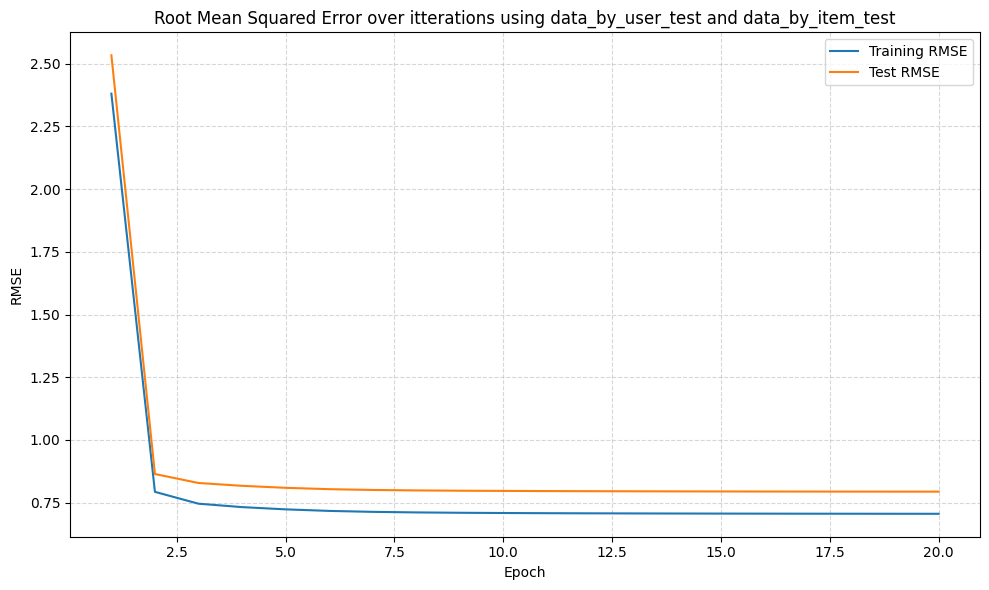

In [39]:
with np.load("my_ratings_parallel.npz") as data:
    loss_train_func = data["loss_train_func"]
    rmse_train_32m_list = data["rmse_train_32m_list"]
    rmse_test_32m_list = data["rmse_test_32m_list"]

epochs_range = range(1, len(loss_train_func) + 1)

plt.figure(figsize=(10, 6))

plt.plot(epochs_range, rmse_train_32m_list, label="Training RMSE")
plt.plot(epochs_range, rmse_test_32m_list, label="Test RMSE")

plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.title("Root Mean Squared Error over itterations using data_by_user_test and data_by_item_test")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig('rmse_over_32M_data.svg', format='svg', bbox_inches='tight')

plt.show()

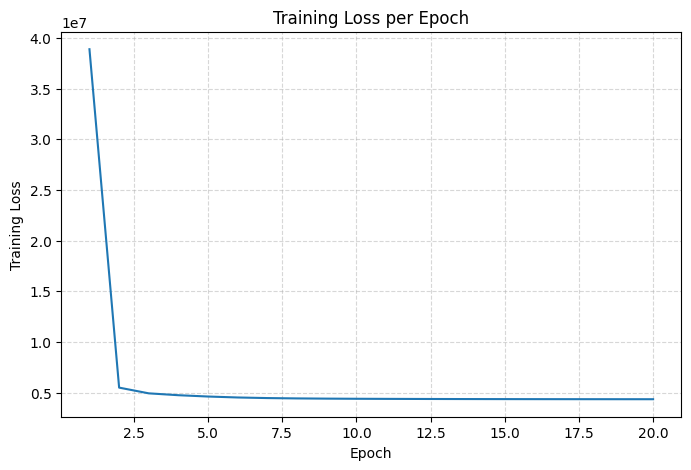

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_train_func)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss per Epoch")
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

Adding a Dummy User

In [36]:
import pandas as pd

In [37]:
movies= pd.read_csv("/content/drive/MyDrive/ml-32m/ml-32m/movies.csv")

In [38]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
